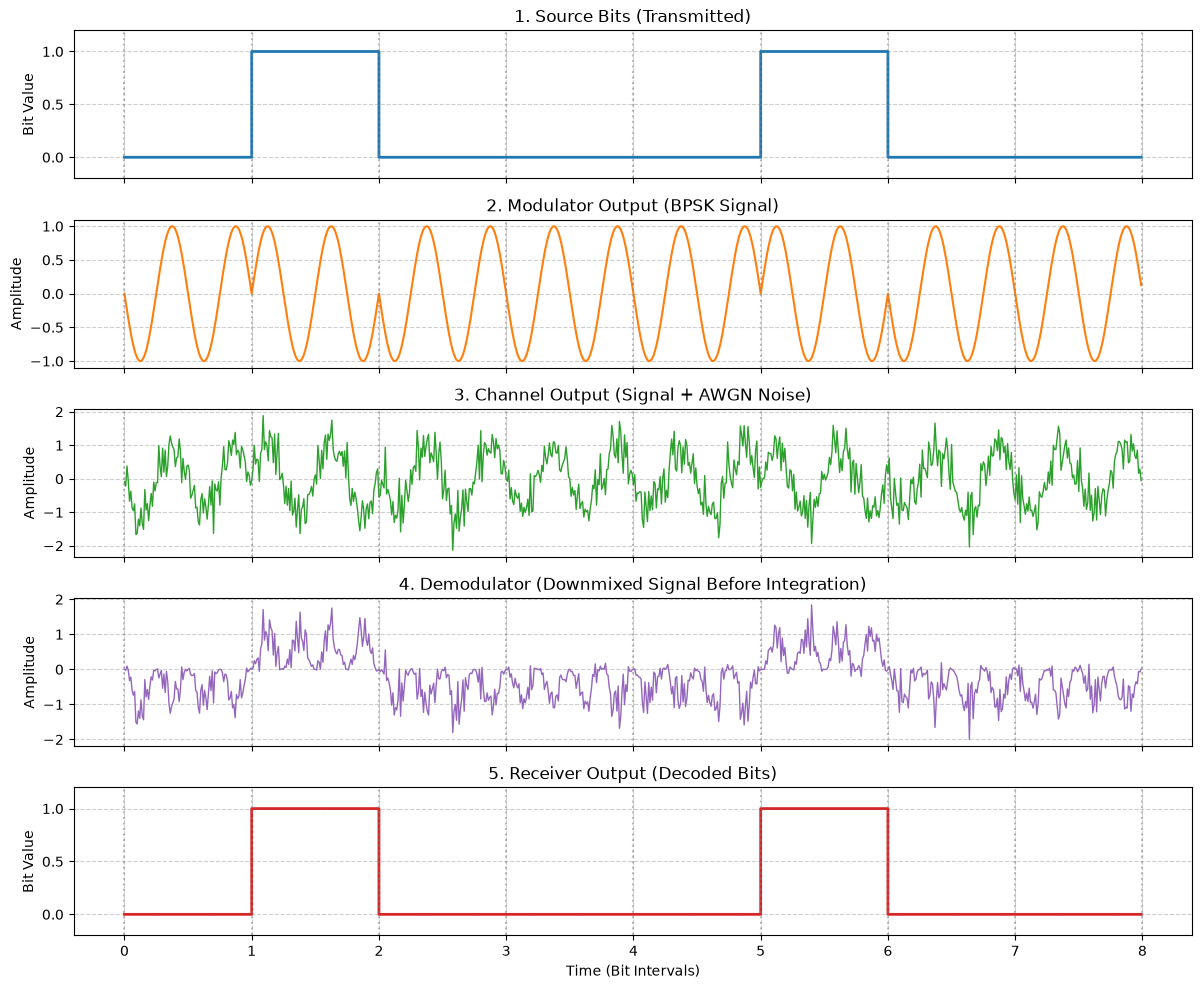

In [1]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Source (Bits)
np.random.seed(42)
num_bits = 8
bits = np.random.randint(0, 2, num_bits)

# Timebase setup
samples_per_bit = 100
t_bit = np.linspace(0, 1, samples_per_bit, endpoint=False)
t_total = np.linspace(0, num_bits, num_bits * samples_per_bit, endpoint=False)

# Expand bits for continuous-time plotting
tx_bit_stream = np.repeat(bits, samples_per_bit)

# 2. Modulator (BPSK)
# Mapping: 0 -> -1, 1 -> +1
carrier_freq = 2  # 2 cycles per bit duration
carrier = np.sin(2 * np.pi * carrier_freq * t_total)
symbols = 2 * bits - 1
tx_symbols = np.repeat(symbols, samples_per_bit)
bpsk_tx = tx_symbols * carrier

# 3. Channel (AWGN Noise Addition)
snr_db = 5  # Signal-to-Noise Ratio in dB
sig_power = np.mean(bpsk_tx**2)
snr_linear = 10 ** (snr_db / 10)
noise_power = sig_power / snr_linear
noise = np.random.normal(0, np.sqrt(noise_power), len(bpsk_tx))
rx_signal = bpsk_tx + noise

# 4. Demodulator (Coherent Detection)
# Multiply by local carrier and integrate over each bit interval
mixed = rx_signal * carrier
rx_bits = []

for i in range(num_bits):
    start = i * samples_per_bit
    end = (i + 1) * samples_per_bit
    # Integrate/accumulate over bit period
    decision_val = np.sum(mixed[start:end])
    rx_bits.append(1 if decision_val > 0 else 0)

# 5. Receiver (Bits)
rx_bit_stream = np.repeat(rx_bits, samples_per_bit)

# Plotting the Signal Flow
fig, axes = plt.subplots(5, 1, figsize=(12, 10), sharex=True)

# Stage 1: Source
axes[0].step(t_total, tx_bit_stream, where="post", color="#1f77b4", lw=2)
axes[0].set_title("1. Source Bits (Transmitted)")
axes[0].set_ylim(-0.2, 1.2)
axes[0].set_ylabel("Bit Value")
axes[0].grid(True, linestyle="--", alpha=0.6)

# Stage 2: Modulator
axes[1].plot(t_total, bpsk_tx, color="#ff7f0e", lw=1.5)
axes[1].set_title("2. Modulator Output (BPSK Signal)")
axes[1].set_ylabel("Amplitude")
axes[1].grid(True, linestyle="--", alpha=0.6)

# Stage 3: Channel
axes[2].plot(t_total, rx_signal, color="#2ca02c", lw=1)
axes[2].set_title("3. Channel Output (Signal + AWGN Noise)")
axes[2].set_ylabel("Amplitude")
axes[2].grid(True, linestyle="--", alpha=0.6)

# Stage 4: Demodulator Mixer
axes[3].plot(t_total, mixed, color="#9467bd", lw=1)
axes[3].set_title("4. Demodulator (Downmixed Signal Before Integration)")
axes[3].set_ylabel("Amplitude")
axes[3].grid(True, linestyle="--", alpha=0.6)

# Stage 5: Receiver Output
axes[4].step(t_total, rx_bit_stream, where="post", color="#d62728", lw=2)
axes[4].set_title("5. Receiver Output (Decoded Bits)")
axes[4].set_ylim(-0.2, 1.2)
axes[4].set_ylabel("Bit Value")
axes[4].set_xlabel("Time (Bit Intervals)")
axes[4].grid(True, linestyle="--", alpha=0.6)

# Add bit markers along top
for i in range(num_bits + 1):
    for ax in axes:
        ax.axvline(i, color="gray", linestyle=":", alpha=0.5)

plt.tight_layout()
plt.savefig("signal_flow_analysis.png", dpi=300, bbox_inches="tight")
plt.show()